STEP 1: ORIGINAL DESIGN MATRIX
x values:
[1000. 1001. 1002. 1003. 1004.]

Design matrix X:
[[      1.    1000. 1000000.]
 [      1.    1001. 1002001.]
 [      1.    1002. 1004004.]
 [      1.    1003. 1006009.]
 [      1.    1004. 1008016.]]

STEP 2: FEATURE SCALES
      Column    Minimum    Maximum   Range       L2 norm
0  Intercept        1.0        1.0     0.0  2.236068e+00
1          x     1000.0     1004.0     4.0  2.240542e+03
2        x^2  1000000.0  1008016.0  8016.0  2.245035e+06

STEP 3: CONDITION NUMBERS
Condition number of X       = 6.024e+11
Condition number of X^T X   = 1.407e+23
cond(X)^2                  = 3.629e+23

Important:
Using normal equations squares the condition number approximately:
cond(X^T X) ≈ cond(X)^2

STEP 4: TRUE MODEL AND RESPONSE VECTOR
True beta:
[1. 2. 3.]

y values:
[3002001. 3008006. 3014017. 3020034. 3026057.]

STEP 5: LEAST-SQUARES SOLUTION USING np.linalg.lstsq
Estimated beta:
[0.99997 2.      3.     ]

Residuals:
[0.]

Rank of X:
3

Singular 

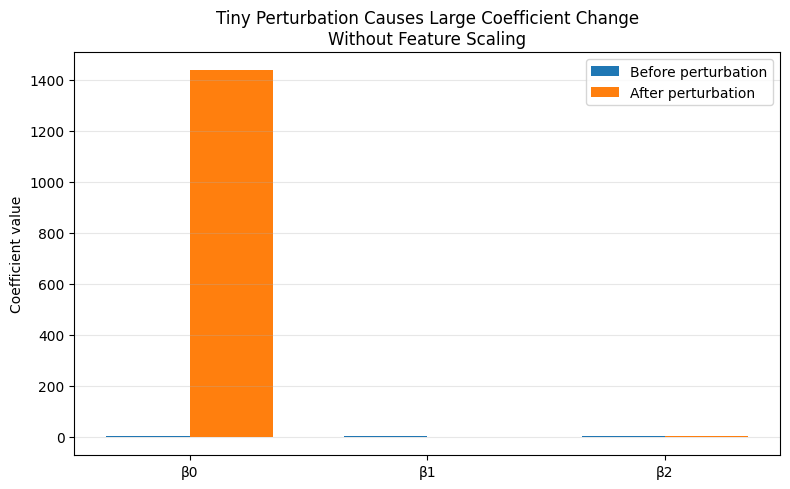


STEP 11: STANDARDIZED FEATURE
Standardized z:
[-1.264911 -0.632456  0.        0.632456  1.264911]

Scaled design matrix X_scaled:
[[ 1.       -1.264911  1.6     ]
 [ 1.       -0.632456  0.4     ]
 [ 1.        0.        0.      ]
 [ 1.        0.632456  0.4     ]
 [ 1.        1.264911  1.6     ]]

STEP 12: FEATURE SCALES AFTER SCALING
      Column   Minimum   Maximum     Range   L2 norm
0  Intercept  1.000000  1.000000  0.000000  2.236068
1          z -1.264911  1.264911  2.529822  2.000000
2        z^2  0.000000  1.600000  1.600000  2.332381

STEP 13: CONDITION NUMBERS AFTER SCALING
Condition number of X_scaled             = 2.757e+00
Condition number of X_scaled^T X_scaled = 7.600e+00

Improvement factor:
cond(X) / cond(X_scaled) = 2.185e+11

STEP 14: FIT SCALED MODEL BEFORE AND AFTER PERTURBATION
Estimated alpha before perturbation:
[3014017.          9508.968924       7.5     ]

Estimated alpha after perturbation:
[3014016.999143    9508.965762       7.503571]

Absolute change in al

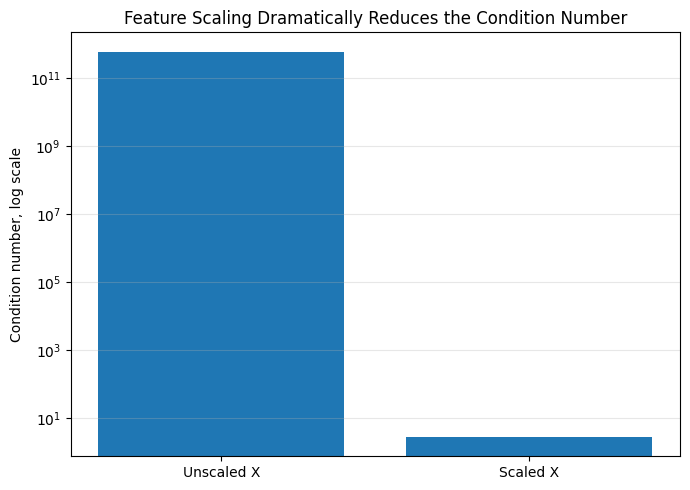


STEP 18: NORMAL EQUATIONS CONDITION NUMBER TABLE
              Matrix  Condition number
0                  X      6.024139e+11
1                XᵀX      1.406508e+23
2           X_scaled      2.756808e+00
3  X_scaledᵀX_scaled      7.599992e+00


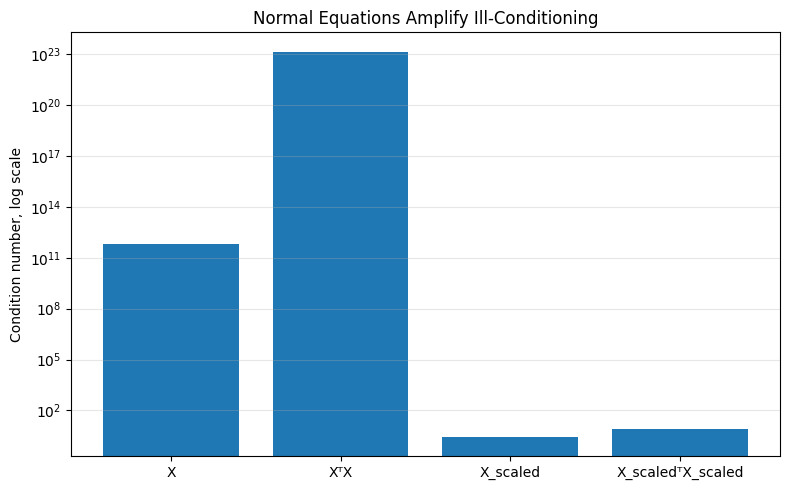

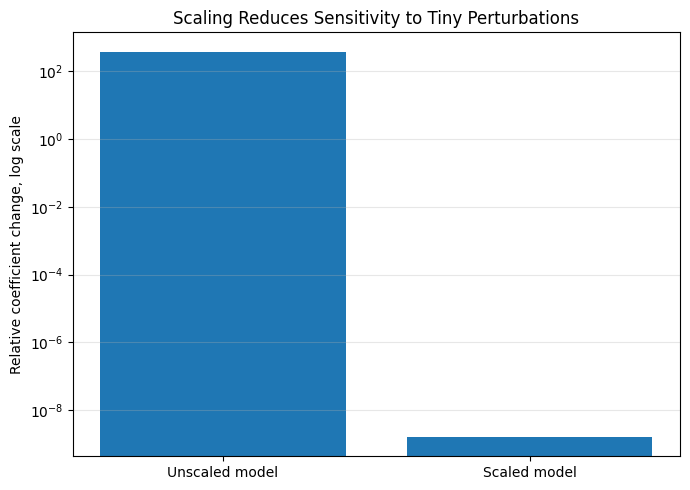


STEP 20: PREDICTION TABLE
        x  Original y  Perturbed y  Prediction unscaled before  \
0  1000.0   3002001.0   3002001.01                   3002001.0   
1  1001.0   3008006.0   3008006.00                   3008006.0   
2  1002.0   3014017.0   3014017.00                   3014017.0   
3  1003.0   3020034.0   3020034.00                   3020034.0   
4  1004.0   3026057.0   3026057.00                   3026057.0   

   Prediction unscaled after  Prediction scaled before  \
0               3.002001e+06                 3002001.0   
1               3.008006e+06                 3008006.0   
2               3.014017e+06                 3014017.0   
3               3.020034e+06                 3020034.0   
4               3.026057e+06                 3026057.0   

   Prediction scaled after  
0             3.002001e+06  
1             3.008006e+06  
2             3.014017e+06  
3             3.020034e+06  
4             3.026057e+06  


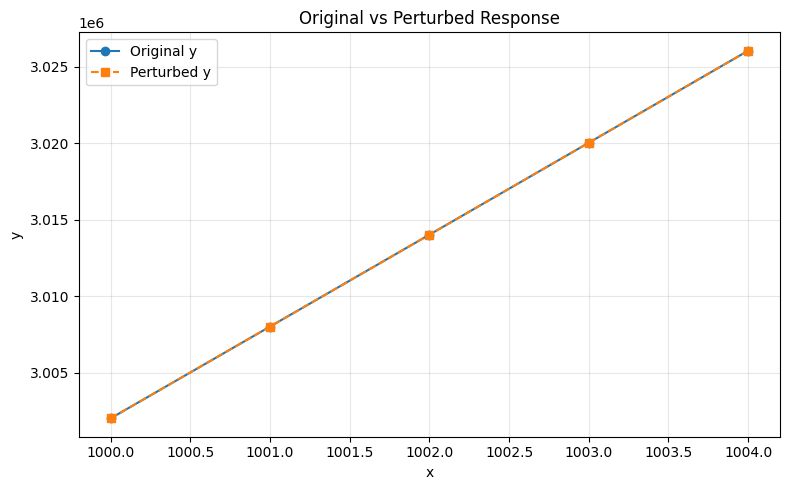


STEP 22: SINGULAR VALUES
   Index  Singular values of X  Singular values of X_scaled
0      1          2.245036e+06                     3.037441
1      2          3.162259e+00                     2.000000
2      3          3.726733e-06                     1.101796


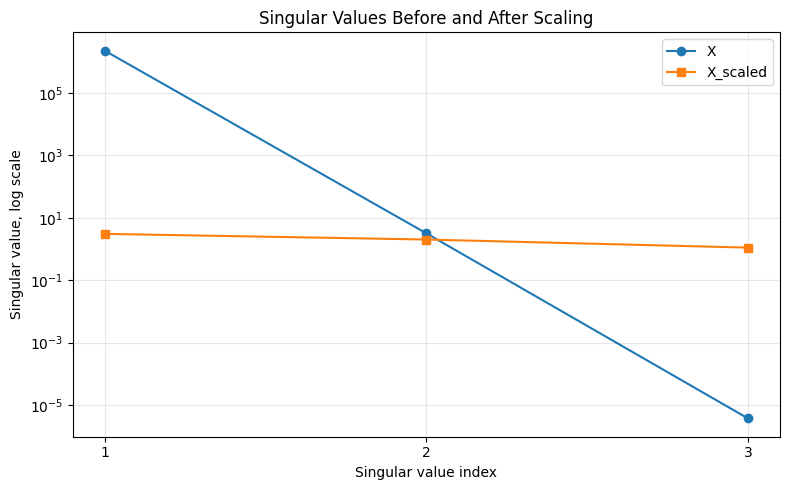


FINAL INTERPRETATION
1. The original matrix X has columns with very different scales: 1, x, and x^2.
2. This makes X extremely ill-conditioned.
3. The condition number of X^T X is much larger because normal equations amplify ill-conditioning.
4. A tiny perturbation in y can create a large change in the estimated coefficients.
5. After standardizing x, the condition number becomes much smaller.
6. The scaled least-squares problem is numerically much more stable.
7. In practice, use centering/scaling and prefer QR or SVD-based solvers instead of direct normal equations.

Main equations:
cond(X) = sigma_max(X) / sigma_min(X)
cond(X^T X) ≈ cond(X)^2
z = (x - mean(x)) / SD(x)


In [1]:
# ============================================================
# Feature Scaling, Condition Number, and Stability in LS
# Complete step-by-step numerical example for Jupyter Notebook
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

# ============================================================
# Step 1: Create an ill-conditioned least-squares problem
# ============================================================

x = np.array([1000, 1001, 1002, 1003, 1004], dtype=float)

# Polynomial regression design matrix:
# y = beta0 + beta1*x + beta2*x^2
X = np.column_stack([
    np.ones_like(x),
    x,
    x**2
])

print("=" * 70)
print("STEP 1: ORIGINAL DESIGN MATRIX")
print("=" * 70)

print("x values:")
print(x)

print("\nDesign matrix X:")
print(X)


# ============================================================
# Step 2: Show feature scales
# ============================================================

column_names = ["Intercept", "x", "x^2"]

scale_table = pd.DataFrame({
    "Column": column_names,
    "Minimum": X.min(axis=0),
    "Maximum": X.max(axis=0),
    "Range": X.max(axis=0) - X.min(axis=0),
    "L2 norm": np.linalg.norm(X, axis=0)
})

print("\n" + "=" * 70)
print("STEP 2: FEATURE SCALES")
print("=" * 70)
print(scale_table)


# ============================================================
# Step 3: Compute condition numbers
# ============================================================

cond_X = np.linalg.cond(X)
cond_XTX = np.linalg.cond(X.T @ X)

print("\n" + "=" * 70)
print("STEP 3: CONDITION NUMBERS")
print("=" * 70)

print(f"Condition number of X       = {cond_X:.3e}")
print(f"Condition number of X^T X   = {cond_XTX:.3e}")
print(f"cond(X)^2                  = {cond_X**2:.3e}")

print("\nImportant:")
print("Using normal equations squares the condition number approximately:")
print("cond(X^T X) ≈ cond(X)^2")


# ============================================================
# Step 4: Generate y from a true model
# ============================================================

beta_true = np.array([1, 2, 3], dtype=float)

# True model:
# y = 1 + 2x + 3x^2
y = X @ beta_true

print("\n" + "=" * 70)
print("STEP 4: TRUE MODEL AND RESPONSE VECTOR")
print("=" * 70)

print("True beta:")
print(beta_true)

print("\ny values:")
print(y)


# ============================================================
# Step 5: Solve least squares using SVD-based solver
# ============================================================

beta_hat, residuals, rank, singular_values = np.linalg.lstsq(X, y, rcond=None)

print("\n" + "=" * 70)
print("STEP 5: LEAST-SQUARES SOLUTION USING np.linalg.lstsq")
print("=" * 70)

print("Estimated beta:")
print(beta_hat)

print("\nResiduals:")
print(residuals)

print("\nRank of X:")
print(rank)

print("\nSingular values of X:")
print(singular_values)


# ============================================================
# Step 6: Solve least squares using normal equations
# ============================================================

beta_normal_eq = np.linalg.solve(X.T @ X, X.T @ y)

print("\n" + "=" * 70)
print("STEP 6: LEAST-SQUARES SOLUTION USING NORMAL EQUATIONS")
print("=" * 70)

print("Estimated beta using normal equations:")
print(beta_normal_eq)

print("\nDifference between lstsq and normal equations:")
print(beta_hat - beta_normal_eq)


# ============================================================
# Step 7: Add a tiny perturbation to y
# ============================================================

y_perturbed = y.copy()
y_perturbed[0] += 0.01

delta_y = y_perturbed - y
relative_perturbation_y = np.linalg.norm(delta_y) / np.linalg.norm(y)

print("\n" + "=" * 70)
print("STEP 7: TINY PERTURBATION IN y")
print("=" * 70)

print("Original y:")
print(y)

print("\nPerturbed y:")
print(y_perturbed)

print(f"\nRelative perturbation ||Δy|| / ||y|| = {relative_perturbation_y:.3e}")


# ============================================================
# Step 8: Refit after perturbation
# ============================================================

beta_hat_perturbed, *_ = np.linalg.lstsq(X, y_perturbed, rcond=None)

relative_change_beta = (
    np.linalg.norm(beta_hat_perturbed - beta_hat) / np.linalg.norm(beta_hat)
)

print("\n" + "=" * 70)
print("STEP 8: REFIT UNSCALED MODEL AFTER PERTURBATION")
print("=" * 70)

print("Estimated beta before perturbation:")
print(beta_hat)

print("\nEstimated beta after perturbation:")
print(beta_hat_perturbed)

print("\nAbsolute change in beta:")
print(beta_hat_perturbed - beta_hat)

print(f"\nRelative change in beta = {relative_change_beta:.3e}")


# ============================================================
# Step 9: Coefficient table for unscaled model
# ============================================================

coef_table_unscaled = pd.DataFrame({
    "Coefficient": ["beta0", "beta1", "beta2"],
    "Before perturbation": beta_hat,
    "After perturbation": beta_hat_perturbed,
    "Absolute change": beta_hat_perturbed - beta_hat
})

print("\n" + "=" * 70)
print("STEP 9: UNSCALED COEFFICIENT TABLE")
print("=" * 70)

print(coef_table_unscaled)


# ============================================================
# Step 10: Plot coefficient instability without scaling
# ============================================================

plt.figure(figsize=(8, 5))

indices = np.arange(len(beta_hat))
width = 0.35

plt.bar(indices - width / 2, beta_hat, width, label="Before perturbation")
plt.bar(indices + width / 2, beta_hat_perturbed, width, label="After perturbation")

plt.xticks(indices, ["β0", "β1", "β2"])
plt.ylabel("Coefficient value")
plt.title("Tiny Perturbation Causes Large Coefficient Change\nWithout Feature Scaling")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 11: Standardize x
# ============================================================

z = (x - np.mean(x)) / np.std(x, ddof=1)

X_scaled = np.column_stack([
    np.ones_like(z),
    z,
    z**2
])

print("\n" + "=" * 70)
print("STEP 11: STANDARDIZED FEATURE")
print("=" * 70)

print("Standardized z:")
print(z)

print("\nScaled design matrix X_scaled:")
print(X_scaled)


# ============================================================
# Step 12: Feature scales after standardization
# ============================================================

scale_table_scaled = pd.DataFrame({
    "Column": ["Intercept", "z", "z^2"],
    "Minimum": X_scaled.min(axis=0),
    "Maximum": X_scaled.max(axis=0),
    "Range": X_scaled.max(axis=0) - X_scaled.min(axis=0),
    "L2 norm": np.linalg.norm(X_scaled, axis=0)
})

print("\n" + "=" * 70)
print("STEP 12: FEATURE SCALES AFTER SCALING")
print("=" * 70)

print(scale_table_scaled)


# ============================================================
# Step 13: Condition numbers after scaling
# ============================================================

cond_X_scaled = np.linalg.cond(X_scaled)
cond_X_scaled_TX = np.linalg.cond(X_scaled.T @ X_scaled)

print("\n" + "=" * 70)
print("STEP 13: CONDITION NUMBERS AFTER SCALING")
print("=" * 70)

print(f"Condition number of X_scaled             = {cond_X_scaled:.3e}")
print(f"Condition number of X_scaled^T X_scaled = {cond_X_scaled_TX:.3e}")

print("\nImprovement factor:")
print(f"cond(X) / cond(X_scaled) = {cond_X / cond_X_scaled:.3e}")


# ============================================================
# Step 14: Fit scaled model before and after perturbation
# ============================================================

alpha_hat, *_ = np.linalg.lstsq(X_scaled, y, rcond=None)
alpha_hat_perturbed, *_ = np.linalg.lstsq(X_scaled, y_perturbed, rcond=None)

relative_change_alpha = (
    np.linalg.norm(alpha_hat_perturbed - alpha_hat) / np.linalg.norm(alpha_hat)
)

print("\n" + "=" * 70)
print("STEP 14: FIT SCALED MODEL BEFORE AND AFTER PERTURBATION")
print("=" * 70)

print("Estimated alpha before perturbation:")
print(alpha_hat)

print("\nEstimated alpha after perturbation:")
print(alpha_hat_perturbed)

print("\nAbsolute change in alpha:")
print(alpha_hat_perturbed - alpha_hat)

print(f"\nRelative change in alpha = {relative_change_alpha:.3e}")


# ============================================================
# Step 15: Coefficient table for scaled model
# ============================================================

coef_table_scaled = pd.DataFrame({
    "Coefficient": ["alpha0", "alpha1", "alpha2"],
    "Before perturbation": alpha_hat,
    "After perturbation": alpha_hat_perturbed,
    "Absolute change": alpha_hat_perturbed - alpha_hat
})

print("\n" + "=" * 70)
print("STEP 15: SCALED COEFFICIENT TABLE")
print("=" * 70)

print(coef_table_scaled)


# ============================================================
# Step 16: Compare unscaled and scaled models
# ============================================================

comparison_table = pd.DataFrame({
    "Case": ["Unscaled X", "Scaled X"],
    "Condition number": [cond_X, cond_X_scaled],
    "Condition number of normal equations": [cond_XTX, cond_X_scaled_TX],
    "Relative change in coefficients": [
        relative_change_beta,
        relative_change_alpha
    ]
})

print("\n" + "=" * 70)
print("STEP 16: COMPARISON TABLE")
print("=" * 70)

print(comparison_table)


# ============================================================
# Step 17: Plot condition number improvement
# ============================================================

plt.figure(figsize=(7, 5))

labels = ["Unscaled X", "Scaled X"]
values = [cond_X, cond_X_scaled]

plt.bar(labels, values)
plt.yscale("log")
plt.ylabel("Condition number, log scale")
plt.title("Feature Scaling Dramatically Reduces the Condition Number")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 18: Plot condition numbers of X and X^T X
# ============================================================

normal_eq_table = pd.DataFrame({
    "Matrix": ["X", "XᵀX", "X_scaled", "X_scaledᵀX_scaled"],
    "Condition number": [
        cond_X,
        cond_XTX,
        cond_X_scaled,
        cond_X_scaled_TX
    ]
})

print("\n" + "=" * 70)
print("STEP 18: NORMAL EQUATIONS CONDITION NUMBER TABLE")
print("=" * 70)

print(normal_eq_table)

plt.figure(figsize=(8, 5))

plt.bar(normal_eq_table["Matrix"], normal_eq_table["Condition number"])
plt.yscale("log")
plt.ylabel("Condition number, log scale")
plt.title("Normal Equations Amplify Ill-Conditioning")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 19: Plot coefficient sensitivity before and after scaling
# ============================================================

plt.figure(figsize=(7, 5))

labels = ["Unscaled model", "Scaled model"]
values = [relative_change_beta, relative_change_alpha]

plt.bar(labels, values)
plt.yscale("log")
plt.ylabel("Relative coefficient change, log scale")
plt.title("Scaling Reduces Sensitivity to Tiny Perturbations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 20: Show fitted predictions are still stable
# Important teaching point:
# Even if coefficients change a lot in an ill-conditioned model,
# predictions may sometimes look less affected inside the observed range.
# ============================================================

y_pred_unscaled = X @ beta_hat
y_pred_unscaled_perturbed = X @ beta_hat_perturbed

y_pred_scaled = X_scaled @ alpha_hat
y_pred_scaled_perturbed = X_scaled @ alpha_hat_perturbed

prediction_table = pd.DataFrame({
    "x": x,
    "Original y": y,
    "Perturbed y": y_perturbed,
    "Prediction unscaled before": y_pred_unscaled,
    "Prediction unscaled after": y_pred_unscaled_perturbed,
    "Prediction scaled before": y_pred_scaled,
    "Prediction scaled after": y_pred_scaled_perturbed
})

print("\n" + "=" * 70)
print("STEP 20: PREDICTION TABLE")
print("=" * 70)

print(prediction_table)


# ============================================================
# Step 21: Plot original and perturbed data
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(x, y, marker="o", label="Original y")
plt.plot(x, y_perturbed, marker="s", linestyle="--", label="Perturbed y")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original vs Perturbed Response")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 22: Plot singular values before and after scaling
# ============================================================

singular_values_scaled = np.linalg.svd(X_scaled, compute_uv=False)

singular_table = pd.DataFrame({
    "Index": [1, 2, 3],
    "Singular values of X": singular_values,
    "Singular values of X_scaled": singular_values_scaled
})

print("\n" + "=" * 70)
print("STEP 22: SINGULAR VALUES")
print("=" * 70)

print(singular_table)

plt.figure(figsize=(8, 5))

plt.plot([1, 2, 3], singular_values, marker="o", label="X")
plt.plot([1, 2, 3], singular_values_scaled, marker="s", label="X_scaled")

plt.yscale("log")
plt.xlabel("Singular value index")
plt.ylabel("Singular value, log scale")
plt.title("Singular Values Before and After Scaling")
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 23: Final educational summary
# ============================================================

print("\n" + "=" * 70)
print("FINAL INTERPRETATION")
print("=" * 70)

print("1. The original matrix X has columns with very different scales: 1, x, and x^2.")
print("2. This makes X extremely ill-conditioned.")
print("3. The condition number of X^T X is much larger because normal equations amplify ill-conditioning.")
print("4. A tiny perturbation in y can create a large change in the estimated coefficients.")
print("5. After standardizing x, the condition number becomes much smaller.")
print("6. The scaled least-squares problem is numerically much more stable.")
print("7. In practice, use centering/scaling and prefer QR or SVD-based solvers instead of direct normal equations.")

print("\nMain equations:")
print("cond(X) = sigma_max(X) / sigma_min(X)")
print("cond(X^T X) ≈ cond(X)^2")
print("z = (x - mean(x)) / SD(x)")